# Seeing a robot's state: robot-agnostic streaming with `jaxterity.diagnostics`

> *You can't fix what you can't see.*

A robot is a high-dimensional, fast-moving state vector. When a controller
misbehaves — a joint clips a limit, a velocity spikes, a torque saturates, a
floating base drifts — staring at a `(35,)` array of floats tells you nothing.
You need to **see the body move in 3D** and **scrub the signals** that drove it.

This notebook is the **diagnostics / observability** story of the
[**jaxterity**](https://github.com/) stack:

```
jaxonomy  (JAX sim engine)  →  jaxterity  (robotics: zoo, MJX dynamics,
                                calibrated models, DIAGNOSTICS)  →  jaxility (deploy)
```

The headline: **one logger streams *any* robot.** The fixed-base SO-100 arm, the
floating-base Crazyflie quadrotor, and the 29-DoF Unitree G1 humanoid all flow
through the **same** `RobotRerunLogger` code — because the geometry comes from
**forward kinematics (MJX)**, not from per-robot drawing. Give it a configuration
`q`, it gives you every link's 3D transform, a kinematic skeleton, and per-joint
position / velocity / torque time series, ready to stream to
[Rerun](https://rerun.io).

**What we'll do**

1. Look at *how* the logger turns FK into a 3D view + signals.
2. Confirm it is genuinely robot-agnostic across 3 robots of different topology.
3. Stream a trajectory to a Rerun `.rrd` recording.
4. Inspect the streamed per-joint signals as plots — the thing you'd scrub.
5. The showcase: a **meshed MuJoCo animation** of the G1 with its signals beside it.
6. Why this is *jaxy*, exercises, and takeaways.

In [1]:
# We keep imports light and silence MJX's optional-backend chatter.
import logging
import os
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("absl").setLevel(logging.ERROR)
os.environ.setdefault("JAX_PLATFORMS", "cpu")  # this tutorial is tiny; CPU is plenty

import pathlib  # noqa: E402

import jax  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from jaxterity import zoo  # noqa: E402
from jaxterity.diagnostics import RobotRerunLogger, log_robot_trajectory  # noqa: E402

MEDIA = pathlib.Path("media")
MEDIA.mkdir(exist_ok=True)
print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.9.2 | devices: [CpuDevice(id=0)]


## 1. The logger: forward kinematics → a 3D view + signals

The whole trick lives in one private helper,
`jaxterity.diagnostics.rerun_robot._build_kinematics(robot)`. For *any* robot it:

1. Compiles the robot's MJCF into an **MJX model** — the exact same model the
   differentiable dynamics use.
2. Builds a jitted closure `fk(q) -> (xpos, xquat)` around `mjx.kinematics`,
   returning **every body's world position and orientation**.
3. Records the body tree (`parent_ids`) so a **skeleton** can be drawn as bones
   from each link to its parent.
4. Enumerates the joints with their `qpos` / `qvel` slices, so per-joint
   **position / velocity / torque** signals can be sliced out of the full
   state vectors.

Then `RobotRerunLogger.log_step(q, qd=..., tau=..., time=...)` logs, per step:

| Rerun entity                          | content                              |
|---------------------------------------|--------------------------------------|
| `{ns}/bodies/{link}`                  | `Transform3D` + a small oriented box |
| `{ns}/skeleton`                       | `LineStrips3D` (the bones)           |
| `{ns}/signals/{joint}/position`       | per-joint `q`                        |
| `{ns}/signals/{joint}/velocity`       | per-joint `q̇` (if `qd` given)        |
| `{ns}/signals/{joint}/torque`         | per-joint `τ` (if `tau` given)       |

Crucially: **none of this is robot-specific.** There is no "draw a G1" code path.
Let's prove it.

In [2]:
from jaxterity.diagnostics.rerun_robot import _build_kinematics


def topology(robot):
    fk, body_names, parent_ids, joints, nq, nv = _build_kinematics(robot)
    # FK is a pure function of q: feed the model's default config and read it back
    # to confirm the closure actually runs for this robot.
    import mujoco

    q0 = mujoco.MjModel.from_xml_string(robot.to_mjcf()).qpos0
    xpos, _ = fk(np.asarray(q0))
    assert np.asarray(xpos).shape == (len(body_names), 3)
    # A floating base shows up as nq != nv (its quaternion has 4 coords, 3 DOF).
    return dict(
        nq=nq, nv=nv, nbody=len(body_names), njoint=len(joints), floating=(nq != nv)
    )


robots = {
    "so100  (fixed-base 6-DoF arm)": zoo.load("so100"),
    "crazyflie (floating-base quadrotor)": zoo.load("crazyflie"),
    "unitree_g1 (floating-base 29-DoF)": zoo.unitree_g1.load(floating_base=True),
}

print(
    f"{'robot':36s} {'nq':>3} {'nv':>3} {'#bodies':>8} {'#joints':>8} {'floating':>9}"
)
print("-" * 72)
for label, r in robots.items():
    t = topology(r)
    print(
        f"{label:36s} {t['nq']:>3} {t['nv']:>3} {t['nbody']:>8} "
        f"{t['njoint']:>8} {str(t['floating']):>9}"
    )

robot                                 nq  nv  #bodies  #joints  floating
------------------------------------------------------------------------
Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


so100  (fixed-base 6-DoF arm)          6   6        9        6     False
crazyflie (floating-base quadrotor)    7   6        2        1      True


unitree_g1 (floating-base 29-DoF)     36  35       31       30      True


Three completely different robots — a 6-DoF fixed-base arm, a 2-body quadrotor
with a free joint (note `nq ≠ nv`: the floating base carries a 4-component
quaternion but only 3 rotational DOF), and a 31-body / 29-joint humanoid — and
the **same** `_build_kinematics` handled all of them. The logger never branched
on the robot. That is the entire value proposition: **observability that scales
to your whole zoo for free.**

## 2. A trajectory to look at: a kinematic G1 choreography

To have clean signals to inspect (and a stable showcase animation), we drive the G1
through a **purely kinematic** joint choreography: we *author* joint targets over
time and set `qpos` directly. This is FK-only — guaranteed stable, no integrator,
no contact — exactly the regime where you want to *check* that your kinematics and
your viewer agree before you trust the dynamics.

The motion: the humanoid does a gentle **squat** while **waving** its arms and
twisting at the waist. We also lower the floating base in sync with the squat so
the feet stay on the floor.

In [3]:
import mujoco

g1 = zoo.unitree_g1.load(floating_base=True)
mj = mujoco.MjModel.from_xml_string(g1.to_mjcf())
qadr = {mj.joint(j).name: int(mj.jnt_qposadr[j]) for j in range(mj.njnt)}
dof = {mj.joint(j).name: int(mj.jnt_dofadr[j]) for j in range(mj.njnt)}

STAND_Z = 0.793  # G1 standing pelvis height (from the menagerie keyframe)
DT = 0.02  # 50 Hz
T = 120  # ~2.4 s, one full loop
ts = np.linspace(0.0, 2 * np.pi, T)

q0 = np.array(mj.qpos0)
q0[2] = STAND_Z
qs = np.tile(q0, (T, 1))


def drive(name, amp, phase=0.0, off=0.0):
    qs[:, qadr[name]] = off + amp * np.sin(ts + phase)


# arms wave
drive("left_shoulder_pitch_joint", -1.0, off=-0.1)
drive("left_shoulder_roll_joint", 0.5, off=0.4)
drive("left_elbow_joint", 0.7, off=0.7)
drive("right_shoulder_pitch_joint", 0.5, phase=np.pi, off=-0.1)
drive("right_elbow_joint", 0.5, phase=np.pi, off=0.7)
drive("waist_yaw_joint", 0.3)
# squat envelope 0->1->0
sq = 0.5 * (1.0 - np.cos(ts))
for j in ("left_knee_joint", "right_knee_joint"):
    qs[:, qadr[j]] = 0.7 * sq
for j in (
    "left_hip_pitch_joint",
    "right_hip_pitch_joint",
    "left_ankle_pitch_joint",
    "right_ankle_pitch_joint",
):
    qs[:, qadr[j]] = -0.35 * sq
qs[:, 2] = STAND_Z - 0.12 * sq  # base sinks with the squat

# Velocities straight from the kinematics: q̇ by finite difference, mapped
# joint-qpos -> joint-dof (hinge joints are 1:1; the free base occupies 0:6).
qds = np.zeros((T, mj.nv))
qds[1:, 6:] = np.diff(qs[:, 7:], axis=0) / DT
qds[0, 6:] = qds[1, 6:]

print("qs:", qs.shape, "(T, nq) | qds:", qds.shape, "(T, nv) |  dt =", DT)

qs: (120, 36) (T, nq) | qds: (120, 35) (T, nv) |  dt = 0.02


### Stream it to Rerun

Now the one-liner. `log_robot_trajectory` builds a `RobotRerunLogger` for the G1
and replays every row — link transforms, skeleton, and the joint signals — onto a
Rerun timeline, saving a `.rrd` recording we (or a teammate) can open later with
`rerun media/tutorial_g1_stream.rrd` or the live `spawn=True` viewer.

In [4]:
RRD = MEDIA / "tutorial_g1_stream.rrd"
log_robot_trajectory(
    g1,
    qs,
    qds=qds,
    dt=DT,
    namespace="unitree_g1",
    save_path=str(RRD),  # headless: write a recording (no viewer needed here)
)
print(f"wrote {RRD}  ({RRD.stat().st_size / 1e3:.0f} kB, {T} steps)")
print("open later with:  rerun", RRD)

wrote media/tutorial_g1_stream.rrd  (429 kB, 120 steps)
open later with:  rerun media/tutorial_g1_stream.rrd


### Trying inline Rerun in the notebook

Rerun 0.33 ships `rr.notebook_show()`, which embeds the live viewer in a Jupyter
output cell. We *try* it below. Under a **headless `nbconvert` execution** (how
this notebook is rendered) the interactive WASM viewer typically can't establish
its data stream, so we fall back gracefully — and the next section shows the
streamed signals as static plots, which is exactly what you'd scrub inside the
viewer anyway.

In [5]:
# Best-effort inline viewer. We never let it break the notebook: if the embedded
# viewer can't initialize under headless nbconvert, we say so and move on to the
# static signal panels (section 3), which carry the same information.
inline_ok = False
try:
    import rerun as rr

    rr.init("unitree_g1_inline")
    # Re-log the trajectory into THIS recording so notebook_show has data.
    logger = RobotRerunLogger(g1, namespace="unitree_g1")
    for i in range(T):
        logger.log_step(qs[i], qd=qds[i], time=i * DT)

    rr.notebook_show(width=720, height=420)
    inline_ok = True
    print("Inline Rerun viewer embedded above.")
except Exception as e:  # headless / no widget transport
    print(
        "Inline Rerun viewer not available in this (headless) render:", type(e).__name__
    )
    print("-> Falling back to the saved .rrd + the static signal panels below.")
    print("   To see it live, run locally:")
    print("     python examples/rerun_robot_demo.py --robot unitree_g1")
    print("   or open the recording:  rerun", RRD)

  WARN re_sdk::log_sink: Dropping data in BufferedSink


Inline Rerun viewer not available in this (headless) render: Exception
-> Falling back to the saved .rrd + the static signal panels below.
   To see it live, run locally:
     python examples/rerun_robot_demo.py --robot unitree_g1
   or open the recording:  rerun media/tutorial_g1_stream.rrd


## 3. Signal inspection: what you'd scrub in Rerun

The 3D body is half the story; the other half is the **per-joint signals** the
logger streams under `unitree_g1/signals/{joint}/{position,velocity}`. In the live
viewer these are scrubbable time-series, time-synced to the 3D view. Here we pull
the exact same slices the logger logs and draw them as static panels — this *is*
the "inspect any signal" capability, just rendered to PNG instead of WASM.

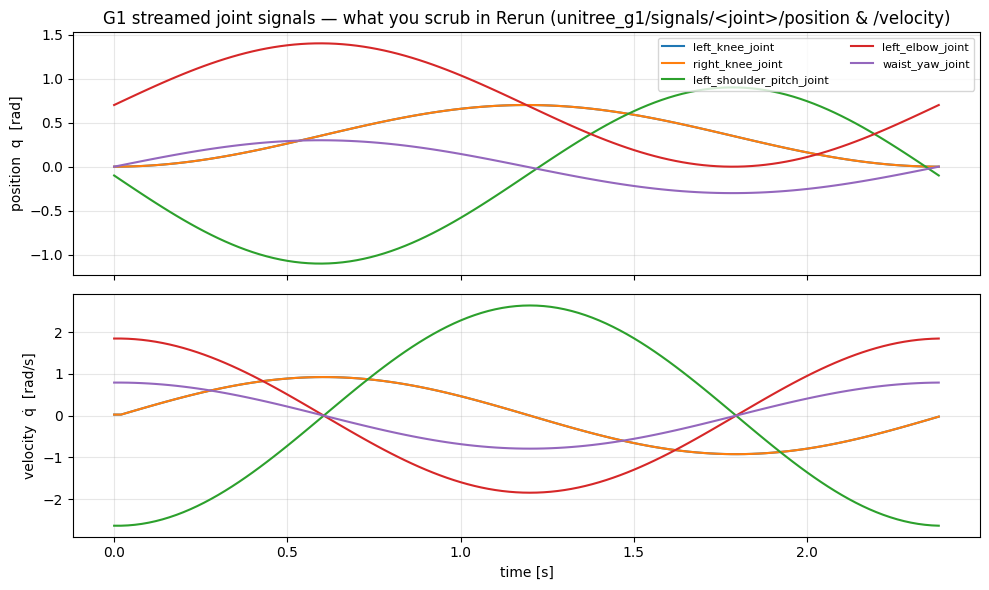

Caption: the squat shows as the synchronized knee/hip swell (bottom-most envelope); the arms wave 180 deg out of phase; the waist twists. Every trace was sliced exactly where RobotRerunLogger logs it.


In [6]:
# Slice the joint signals straight out of (qs, qds) the way the logger does:
# position from q[qpos_adr], velocity from qd[dof_adr].
def joint_signal(name):
    a = qadr[name]
    d = dof[name]
    return qs[:, a], qds[:, d]


watch = [
    "left_knee_joint",
    "right_knee_joint",
    "left_shoulder_pitch_joint",
    "left_elbow_joint",
    "waist_yaw_joint",
]
tline = np.arange(T) * DT

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for name in watch:
    pos, vel = joint_signal(name)
    axes[0].plot(tline, pos, label=name)
    axes[1].plot(tline, vel, label=name)
axes[0].set_ylabel("position  q  [rad]")
axes[0].set_title(
    "G1 streamed joint signals — what you scrub in Rerun "
    "(unitree_g1/signals/<joint>/position & /velocity)"
)
axes[1].set_ylabel("velocity  q̇  [rad/s]")
axes[1].set_xlabel("time [s]")
axes[0].legend(loc="upper right", fontsize=8, ncol=2)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(MEDIA / "tutorial_g1_signals.png", dpi=110)
plt.show()
print(
    "Caption: the squat shows as the synchronized knee/hip swell (bottom-most "
    "envelope); the arms wave 180 deg out of phase; the waist twists. "
    "Every trace was sliced exactly where RobotRerunLogger logs it."
)

**Caption.** Top: joint *positions* over one ~2.4 s loop. Bottom: joint
*velocities* (finite-differenced from the same configurations the logger sees).
The knees trace the squat envelope; the left shoulder-pitch and elbow wave; the
waist yaw twists. In Rerun you'd hover a frame in the 3D view and read these exact
values off time-synced plots — here they're frozen for the page.

## 4. The showcase: a meshed MuJoCo animation, with its signals beside it

Streaming gives you a *fast, schematic* skeleton view. To make the motion
**speak for itself** we render the *same* `qs(t)` through the **full-mesh** G1
model using the shared post-hoc render bridge (`examples/_robot_render.py`).
MuJoCo does **no physics** here — each frame just writes a pose into `qpos` and
calls `mj_forward` (kinematics only), then captures a meshed image. The dynamics
model and the render model have different MJCFs, so the bridge remaps `qpos` by
joint name automatically.

This is the punchline of FK-driven observability: the **schematic stream** (for
debugging signals) and the **photoreal render** (for intuition) are two views of
the **one** configuration trajectory `qs`.

In [7]:
import _robot_render as R

GIF = MEDIA / "tutorial_rerun_streaming.gif"

renderer = R.TrajectoryRenderer("unitree_g1_mjcf", g1.to_mjcf(), size=(640, 640))
camera = dict(distance=2.6, azimuth=140, elevation=-8, lookat=[0, 0, 0.5])
frames = renderer.render(qs, camera=camera, track_body="pelvis", ground_floor=True)

# stride=2 keeps the GIF compact (<5 MB) while staying smooth; the full-res
# `frames` list is reused below for the static showcase panel.
R.write_gif(frames, str(GIF), width=420, fps=12, stride=2)
print(
    f"wrote {GIF}  ({GIF.stat().st_size / 1e6:.2f} MB, "
    f"{len(frames)} frames rendered, every 2nd in the GIF)"
)

wrote media/tutorial_rerun_streaming.gif  (3.43 MB, 120 frames rendered, every 2nd in the GIF)


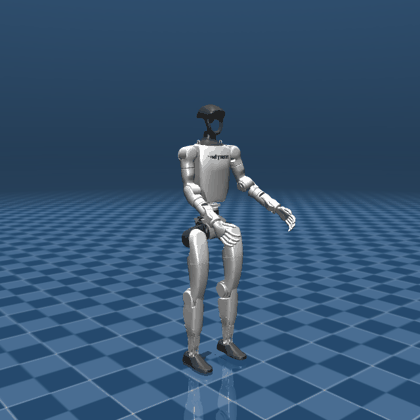

In [8]:
from IPython.display import Image

Image(str(GIF))

**Caption.** The Unitree G1, full meshes, doing the squat-and-wave choreography —
rendered from exactly the `qs` we streamed to Rerun and plotted above. Watch the
knees and hips (the squat in the velocity plot), the arms (the out-of-phase
shoulder/elbow waves), and the waist twist. *Same numbers, three views.*

Let's place a representative frame next to the signals so the correspondence is
unmistakable.

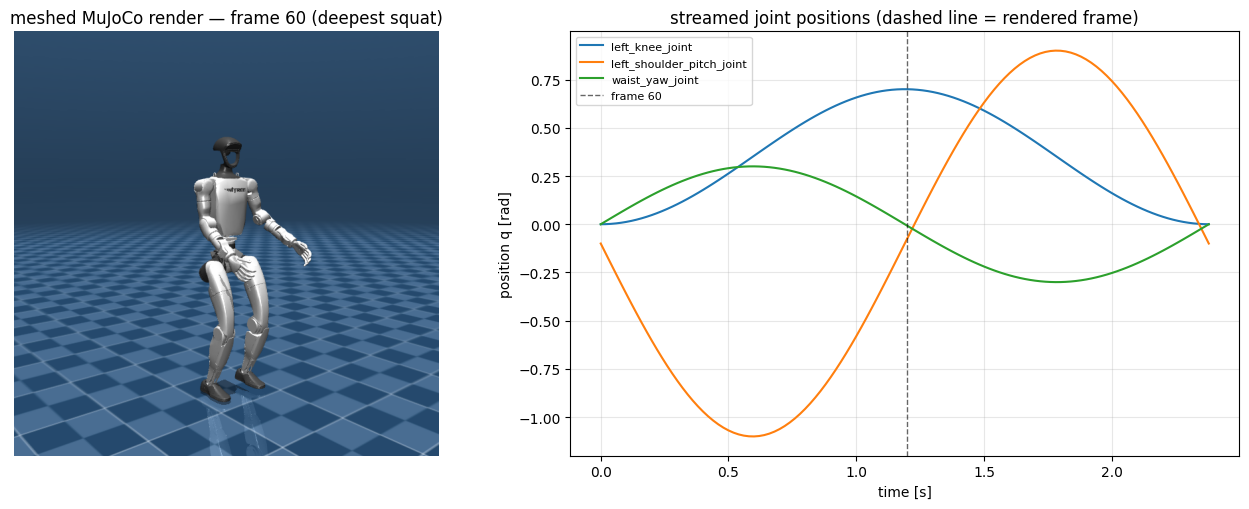

Caption: at the dashed line (frame 60) the knee position is near its peak (deepest squat) — and that is exactly the pose meshed on the left.


In [9]:
# A static "contact sheet": a keyframe of the meshed render + the signal panel,
# making the one-trajectory-three-views point in a single figure.
k = T // 2  # deepest squat
fig, (axL, axR) = plt.subplots(
    1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[1, 1.3])
)
axL.imshow(frames[k])
axL.axis("off")
axL.set_title(f"meshed MuJoCo render — frame {k} (deepest squat)")

for name in ("left_knee_joint", "left_shoulder_pitch_joint", "waist_yaw_joint"):
    pos, _ = joint_signal(name)
    axR.plot(tline, pos, label=name)
axR.axvline(k * DT, color="k", ls="--", lw=1, alpha=0.6, label=f"frame {k}")
axR.set_xlabel("time [s]")
axR.set_ylabel("position q [rad]")
axR.set_title("streamed joint positions (dashed line = rendered frame)")
axR.legend(fontsize=8)
axR.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(MEDIA / "tutorial_g1_showcase_panel.png", dpi=110)
plt.show()
print(
    "Caption: at the dashed line (frame 60) the knee position is near its peak "
    "(deepest squat) — and that is exactly the pose meshed on the left."
)

**Caption.** Left: the meshed G1 at frame 60 (deepest squat). Right: the streamed
joint positions, with a dashed marker at that frame — the knee trace sits at its
peak, matching the bent-knee pose on the left. The 3D animation, the static
render, and the scrubbable signals are *the same data* seen three ways.

## 5. Why this is *jaxy*

- **One FK-driven logger, every topology.** Fixed-base arm, floating-base
  quadrotor, 29-DoF humanoid — all streamed by the same code, because geometry
  comes from `mjx.kinematics`, not per-robot drawing. Add a robot to the zoo and
  it is instantly observable.
- **The viewer shares the dynamics model.** `_build_kinematics` compiles the
  *same* MJX model the differentiable plant uses, so what you *see* is what you
  *simulate* — no separate, drift-prone visualization rig.
- **`fk = jax.jit(...)`, so logging is cheap and composable.** The FK closure is
  a jitted pure function of `q`; the same primitive that powers logging powers
  `vmap`/`grad` over kinematics. Diagnostics and differentiable sim are built on
  one substrate.
- **Schematic + photoreal from one trajectory.** The Rerun stream (debug signals
  fast) and the meshed MuJoCo render (build intuition) are two renderings of the
  single `qs(t)` — guaranteed consistent.

Observability isn't a bolt-on here; it falls out of the same JAX + MJX foundations
as the rest of jaxterity.

## 6. Exercises

1. **Stream a different robot.** Swap `g1` for `zoo.load("so100")` (a fixed-base
   arm) or `zoo.load("crazyflie")`. Build a small `qs` (for SO-100, sweep two
   joints; for the Crazyflie, vary the base quaternion to tilt it) and call
   `log_robot_trajectory`. Notice you change *zero* lines of logger code.

2. **Add torque signals.** `log_step`/`log_robot_trajectory` accept `tau` (shape
   `(nv,)`). Roll the G1 out under its real dynamics
   (`g1.functional_dynamics()`, as in `examples/rerun_robot_demo.py`), pass the
   applied generalized force as `taus`, and add a torque row to the signal panel.

3. **Open the live viewer.** Run
   `python examples/rerun_robot_demo.py --robot unitree_g1` (or `--save out.rrd`
   then `rerun out.rrd`) and scrub the 3D body while watching the joint signals
   update in lock-step — the interactive experience these static panels stand in
   for.

## Takeaways

- `jaxterity.diagnostics.RobotRerunLogger` / `log_robot_trajectory` give you
  **robot-agnostic 3D state streaming + per-joint signal inspection** from a bare
  configuration `q`.
- It works across every zoo topology because the geometry is **forward
  kinematics (MJX)**, not bespoke drawing code — *you can't fix what you can't
  see, and now you can see everything.*
- The streamed `.rrd`, the scrubbable signals, and the meshed MuJoCo showcase render
  are **one trajectory, three views** — consistent by construction.
- It rides the **same JAX + MJX substrate** as the differentiable sim, so
  diagnostics and dynamics never drift apart.

*Next in the stack:* hand a calibrated robot to **jaxility** to cross-compile a
controller to embedded silicon — and use this logger to verify sim parity before
you ship.